# Week 4 — Local Matching Results and Visual Evidence

This notebook prepares the Task 2 and Task 3 results for the presentation. It compares the best Week 4 local-feature method with the Week 3 DCT baseline, summarizes the parameter search, and visualizes how local matches are verified geometrically.

**Run from the repository root, after `python w4/grid_search.py` has created `w4/results/task2_task3_results.csv`.** The final section also needs the QSD1-W4 images, `frames.pkl`, and `gt_corresps.pkl` used for the evaluation.


In [12]:
from pathlib import Path
import sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import cv2

ROOT = Path.cwd()
if not (ROOT / "w4").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
sys.path.insert(0, str(ROOT / "w4"))

from grid_search import load_data, describe, match_score
from cv_descriptors import NORMS

CSV_PATH = ROOT / "w4" / "results" / "task2_task3_results.csv"
FIG_DIR = ROOT / "w4" / "results" / "visualizations"
FIG_DIR.mkdir(parents=True, exist_ok=True)

results = pd.read_csv(CSV_PATH)
local = results[results["method"] == "week4_local"].copy()
baseline = results[results["method"] == "week3_dct_baseline"].iloc[0]
best = local.sort_values(["map@5", "unknown_f1", "map@1"], ascending=False).iloc[0]
local["setting"] = local.apply(
    lambda r: f"{r['descriptor']} | {r['color']} | CLAHE={r['clahe']} | {r['keypoint_detector']}", axis=1
)

plt.rcParams.update({"figure.dpi": 120, "axes.spines.top": False, "axes.spines.right": False})
print(f"Configurations evaluated: {len(local)}")
print("Best Week 4 configuration:")
display(best.to_frame("value"))

Configurations evaluated: 36
Best Week 4 configuration:


,value
method,week4_local
descriptor,orb
color,gray
clahe,True
keypoint_detector,descriptor_default
unknown_threshold,14.5
unknown_f1,0.965517
map@1,0.965517
map@5,0.965517


## 1. Overall evaluation: Week 4 vs Week 3

The first chart answers the main evaluation question. **mAP@1 and mAP@5 measure retrieval among known paintings**; **unknown F1 measures rejection of unknown paintings**. These are separate metrics, so the figure presents all three rather than combining them into one score.


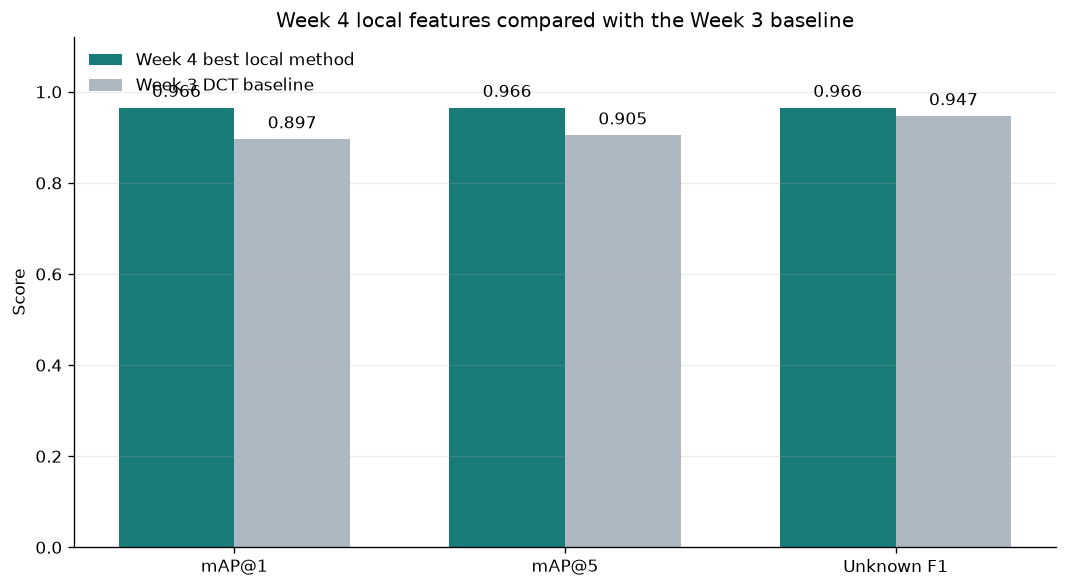

mAP@5 change: +0.060 (+6.0 percentage points)


In [13]:
metrics = ["map@1", "map@5", "unknown_f1"]
metric_names = ["mAP@1", "mAP@5", "Unknown F1"]
week4_values = best[metrics].astype(float).to_numpy()
week3_values = baseline[metrics].astype(float).to_numpy()

x = np.arange(len(metrics))
width = 0.35
fig, ax = plt.subplots(figsize=(9, 5))
bars4 = ax.bar(x - width/2, week4_values, width, label="Week 4 best local method", color="#197c78")
bars3 = ax.bar(x + width/2, week3_values, width, label="Week 3 DCT baseline", color="#aeb8c2")
ax.bar_label(bars4, fmt="%.3f", padding=4)
ax.bar_label(bars3, fmt="%.3f", padding=4)
ax.set_xticks(x, metric_names)
ax.set_ylim(0, 1.12)
ax.set_ylabel("Score")
ax.set_title("Week 4 local features compared with the Week 3 baseline")
ax.legend(frameon=False)
ax.grid(axis="y", alpha=.22)
plt.tight_layout()
plt.savefig(FIG_DIR / "week4_vs_week3.png", bbox_inches="tight")
plt.show()

print(f"mAP@5 change: {week4_values[1] - week3_values[1]:+.3f} ({(week4_values[1] - week3_values[1])*100:+.1f} percentage points)")

### What to say

The best Week 4 configuration retrieves the correct painting more often than the Week 3 DCT baseline on this evaluation set. The unknown F1 score is shown separately because it measures a different decision: whether to identify a painting as unknown.


## 2. Which settings performed best?

This chart ranks the strongest Week 4 configurations by mAP@5. The setting label includes descriptor, color representation, CLAHE, and keypoint detector. Near-ties are useful to report as evidence that performance is stable across several settings; avoid claiming a meaningful difference when scores are identical.


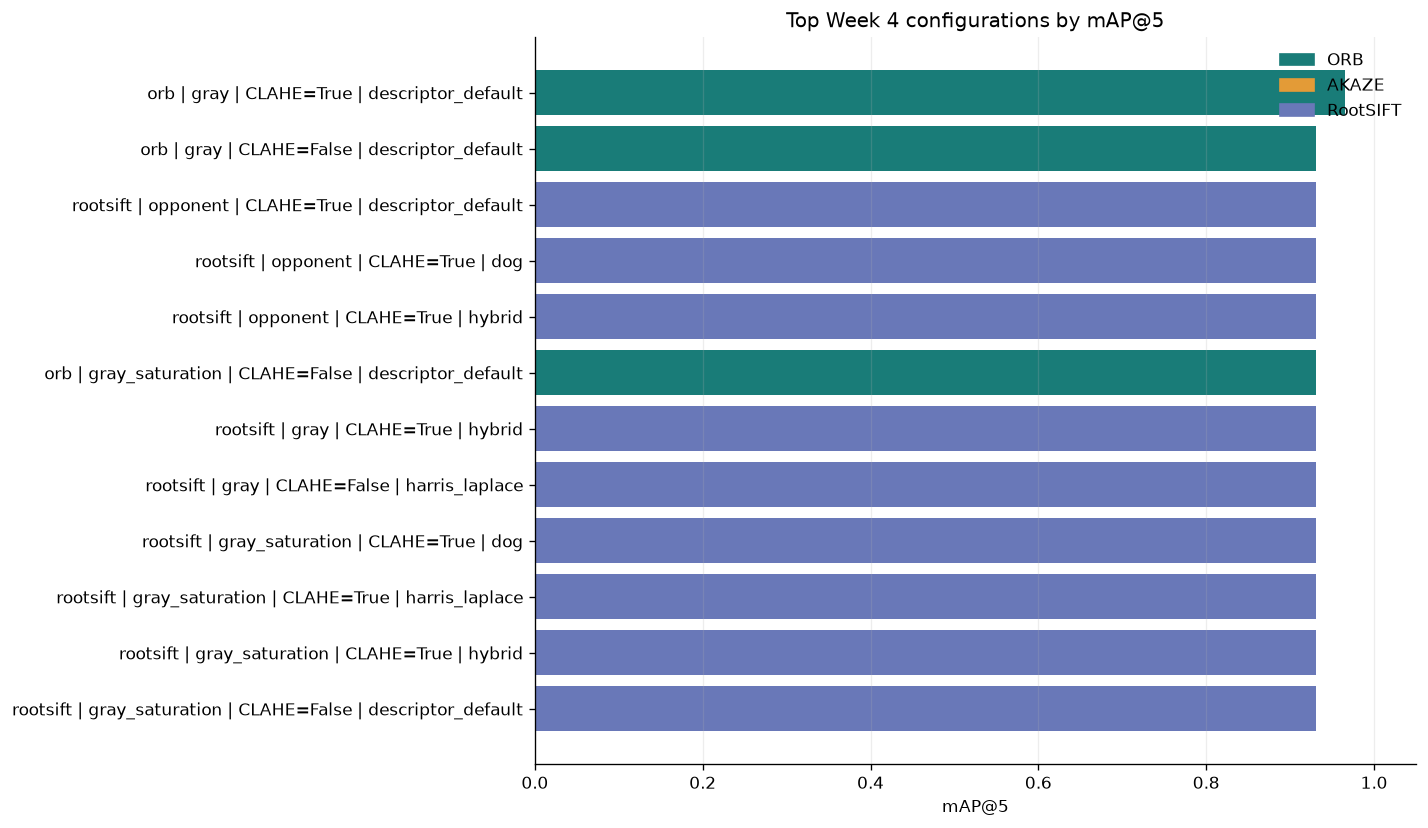

,descriptor,color,clahe,keypoint_detector,unknown_threshold,unknown_f1,map@1,map@5
0,orb,gray,True,descriptor_default,14.5,0.965517,0.965517,0.965517
1,orb,gray,False,descriptor_default,20.5,0.982456,0.931034,0.931034
2,rootsift,opponent,True,descriptor_default,4.5,0.965517,0.931034,0.931034
3,rootsift,opponent,True,dog,4.5,0.965517,0.931034,0.931034
4,rootsift,opponent,True,hybrid,4.5,0.965517,0.931034,0.931034
5,orb,gray_saturation,False,descriptor_default,8.5,0.965517,0.931034,0.931034
6,rootsift,gray,True,hybrid,34.0,0.964286,0.931034,0.931034
7,rootsift,gray,False,harris_laplace,10.0,0.964286,0.931034,0.931034
8,rootsift,gray_saturation,True,dog,9.5,0.964286,0.931034,0.931034
9,rootsift,gray_saturation,True,harris_laplace,6.5,0.964286,0.931034,0.931034


In [14]:
top = local.sort_values(["map@5", "unknown_f1", "map@1"], ascending=False).head(12).copy()
top = top.iloc[::-1]
fig, ax = plt.subplots(figsize=(12, 7))
colors = top["descriptor"].map({"orb": "#197c78", "akaze": "#e39b37", "rootsift": "#6978b8"}).fillna("#888888")
ax.barh(top["setting"], top["map@5"], color=colors)
ax.set_xlim(0, 1.05)
ax.set_xlabel("mAP@5")
ax.set_title("Top Week 4 configurations by mAP@5")
ax.grid(axis="x", alpha=.22)
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color="#197c78", label="ORB"), Patch(color="#e39b37", label="AKAZE"), Patch(color="#6978b8", label="RootSIFT")], frameon=False)
plt.tight_layout()
plt.savefig(FIG_DIR / "top_configurations_map5.png", bbox_inches="tight")
plt.show()

display(local.sort_values(["map@5", "unknown_f1", "map@1"], ascending=False)[["descriptor", "color", "clahe", "keypoint_detector", "unknown_threshold", "unknown_f1", "map@1", "map@5"]].head(10).reset_index(drop=True))

## 3. Retrieval quality and unknown rejection together

Each point is one tested Week 4 configuration. Points farther right have higher mAP@5; points higher up have higher unknown F1. This makes the trade-off visible and shows whether the selected configuration is strong on both tasks.


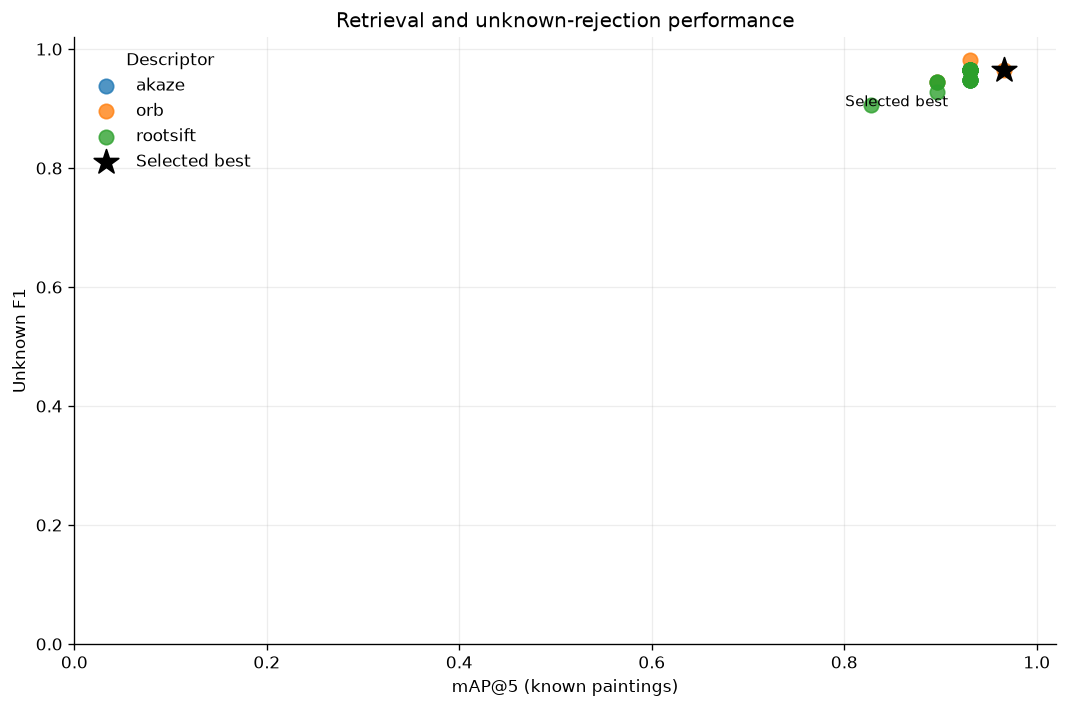

In [15]:
fig, ax = plt.subplots(figsize=(9, 6))
for descriptor, group in local.groupby("descriptor"):
    ax.scatter(group["map@5"], group["unknown_f1"], s=75, alpha=.78, label=descriptor)
ax.scatter([best["map@5"]], [best["unknown_f1"]], s=240, marker="*", color="black", label="Selected best", zorder=5)
ax.annotate("Selected best", (best["map@5"], best["unknown_f1"]), xytext=(-95, -22), textcoords="offset points", fontsize=9)
ax.set_xlim(0, 1.02)
ax.set_ylim(0, 1.02)
ax.set_xlabel("mAP@5 (known paintings)")
ax.set_ylabel("Unknown F1")
ax.set_title("Retrieval and unknown-rejection performance")
ax.grid(alpha=.22)
ax.legend(title="Descriptor", frameon=False)
plt.tight_layout()
plt.savefig(FIG_DIR / "map5_vs_unknown_f1.png", bbox_inches="tight")
plt.show()

## 4. How tentative local matches are verified

For the selected method, local descriptors first propose tentative correspondences using the Lowe ratio test. RANSAC then estimates a homography and keeps correspondences consistent with the same planar transformation. The next figure shows both stages on QSD1-W4 crops. It is qualitative evidence: the numerical evaluation remains the mAP and unknown F1 above.

The notebook selects up to four known query crops. In each row, the left panel shows tentative matches and the right panel shows the geometrically verified inliers. The title reports the ground-truth museum ID, the top-ranked result, and the inlier count.


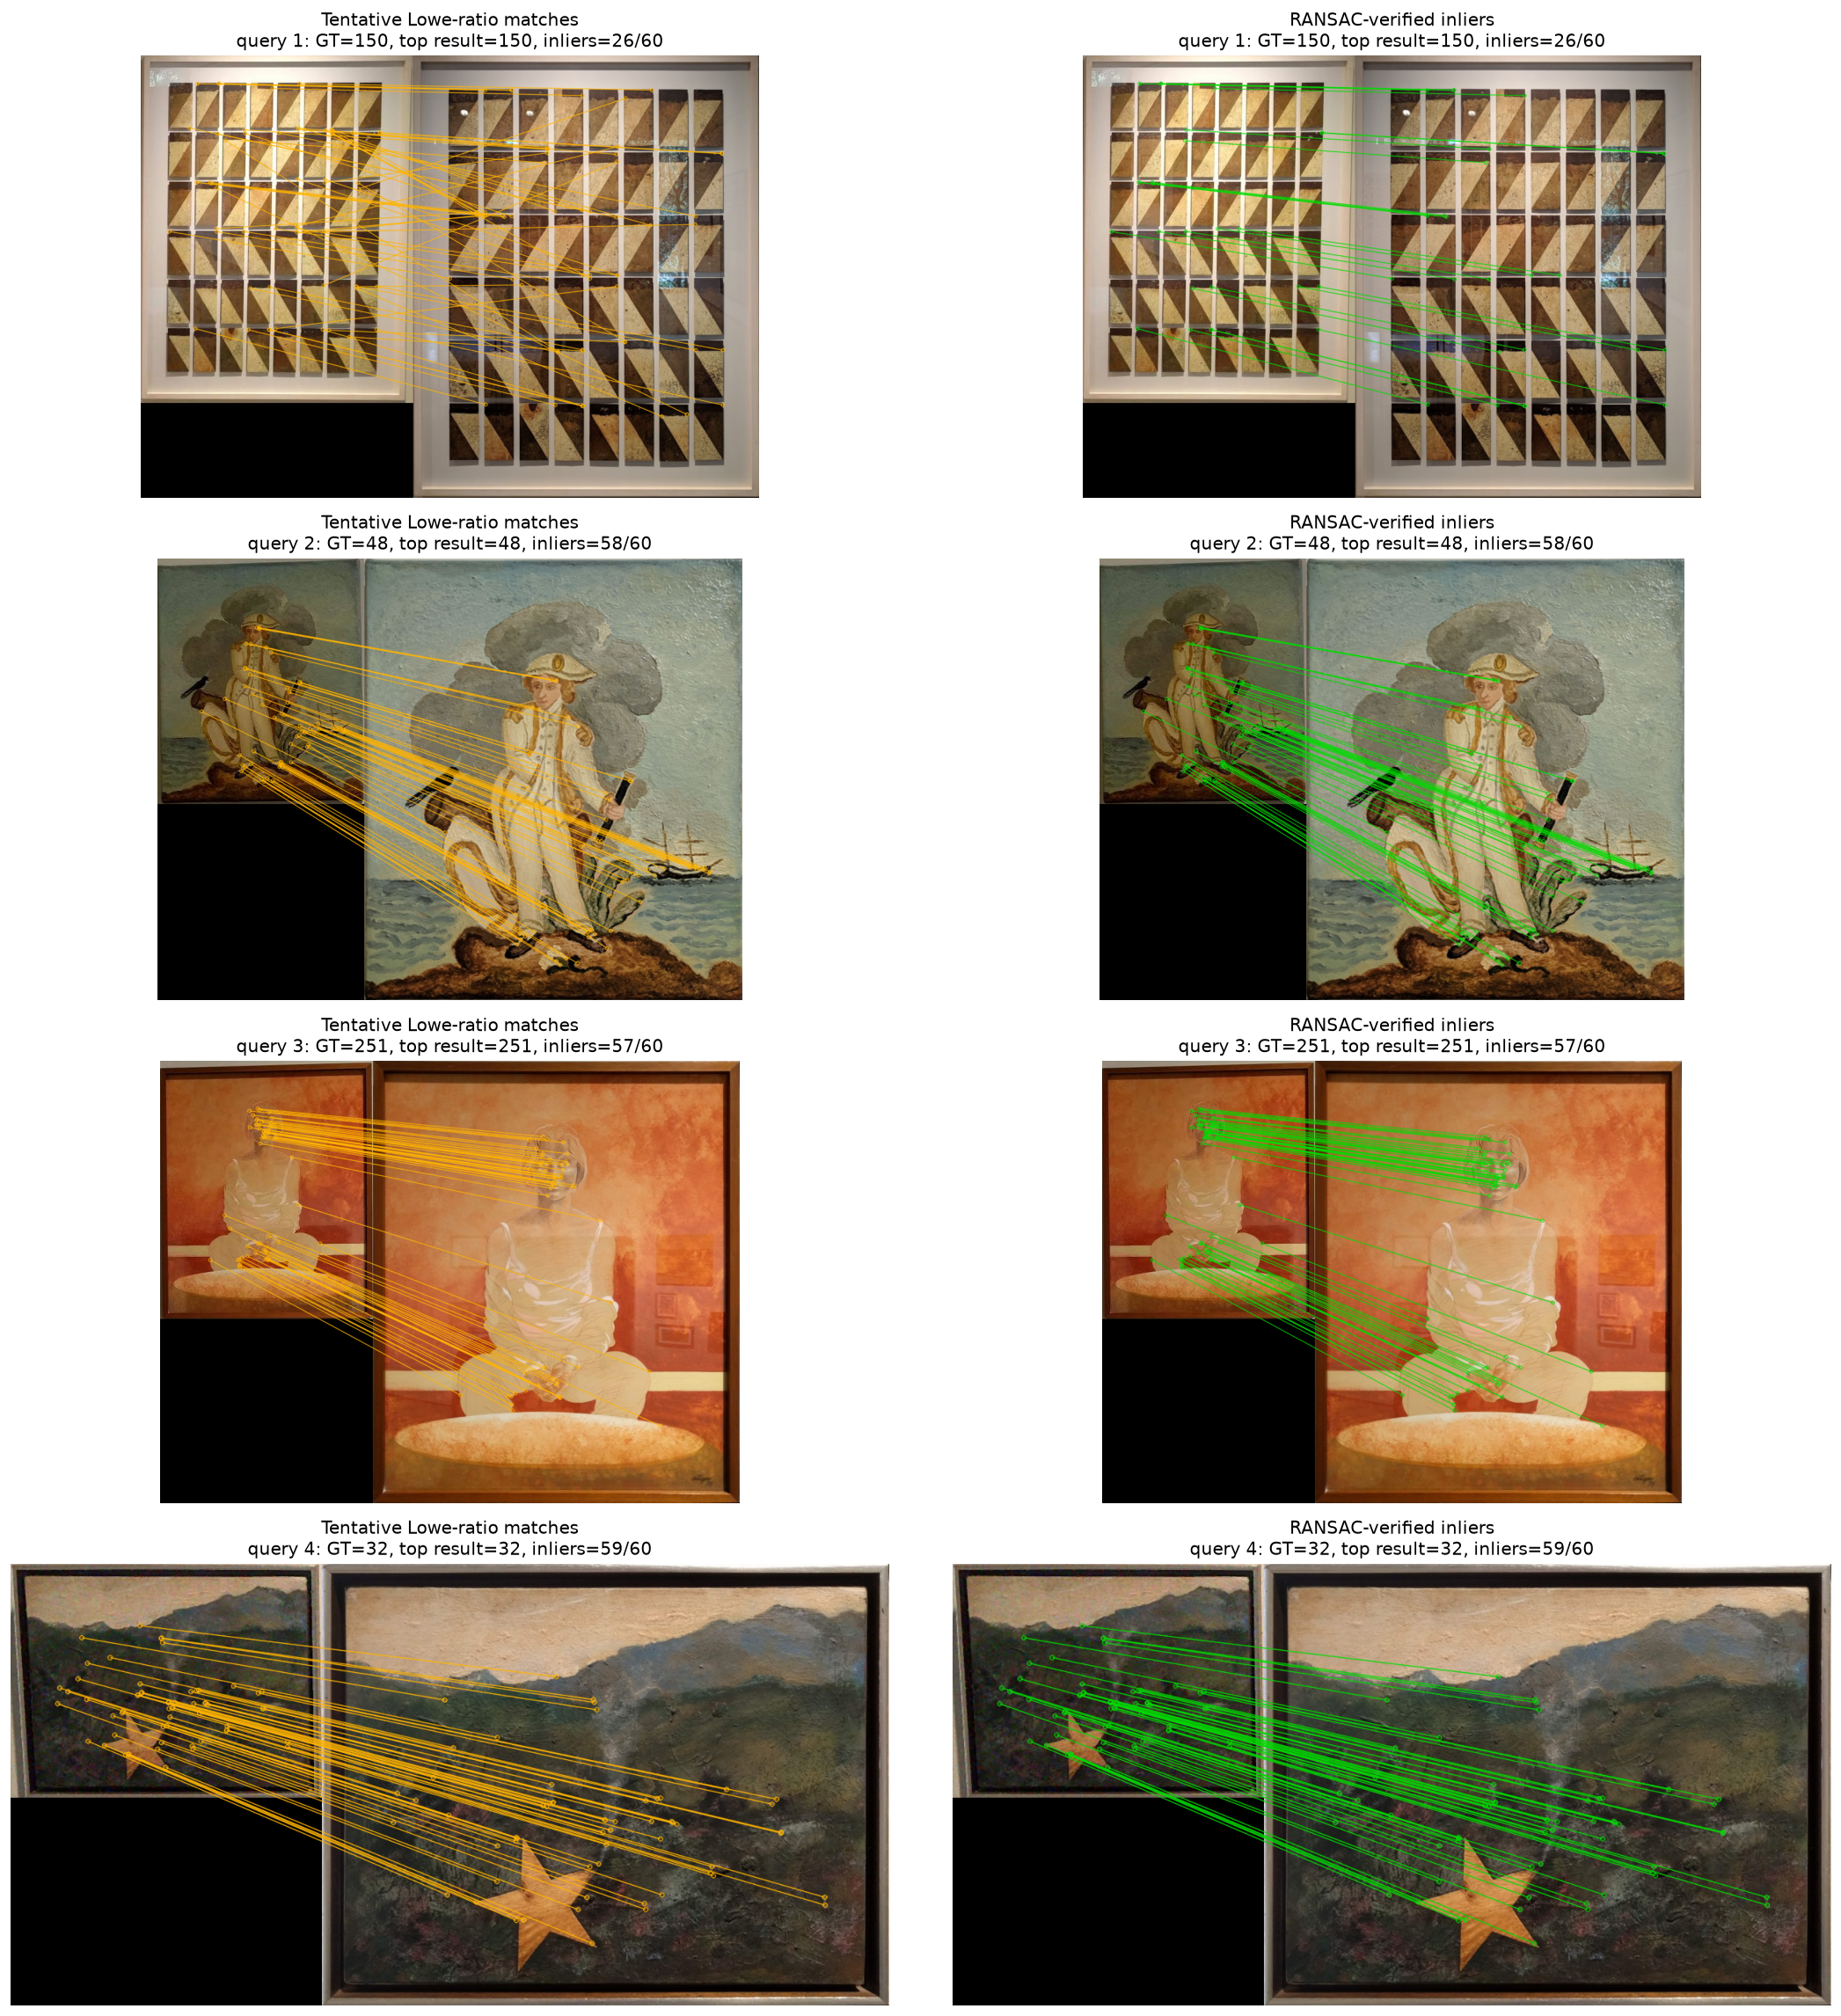

In [16]:
# Load the same frame crops and gallery used by grid_search.py.
db_ids, db_images, query_images, labels, _ = load_data()
config = best.to_dict()
descriptor = str(config["descriptor"])
color = str(config["color"])
clahe = str(config["clahe"]).strip().lower() == "true" if isinstance(config["clahe"], str) else bool(config["clahe"])
detector = config["keypoint_detector"]
if pd.isna(detector) or detector == "descriptor_default":
    detector = None
norm = NORMS[descriptor]
db_features = [describe(image, descriptor, color, clahe, detector) for image in db_images]


def tentative_and_inliers(query_feature, museum_feature):
    q_points, q_desc = query_feature
    m_points, m_desc = museum_feature
    if q_desc is None or m_desc is None or len(q_desc) < 2 or len(m_desc) < 2:
        return [], []
    pairs = cv2.BFMatcher(norm).knnMatch(q_desc, m_desc, k=2)
    good = [a for pair in pairs if len(pair) == 2 for a, b in [pair] if a.distance < 0.75 * b.distance]
    if len(good) < 4:
        return good, [0] * len(good)
    src = q_points[[m.queryIdx for m in good]]
    dst = m_points[[m.trainIdx for m in good]]
    try:
        _, mask = cv2.findHomography(src, dst, cv2.RANSAC, 5.0)
    except cv2.error:
        mask = None
    inliers = mask.ravel().astype(int).tolist() if mask is not None else [0] * len(good)
    return good[:60], inliers[:60]

known_indices = np.flatnonzero(labels >= 0)[:4]
if len(known_indices) == 0:
    print("No known paintings found in the evaluation labels.")
else:
    fig, axes = plt.subplots(len(known_indices), 2, figsize=(18, 4.8 * len(known_indices)), squeeze=False)
    for row_axes, query_idx in zip(axes, known_indices):
        query_image = query_images[query_idx]
        query_feature = describe(query_image, descriptor, color, clahe, detector)
        scores = [match_score(query_feature, feature, norm) for feature in db_features]
        top_idx = int(np.argmax(scores))
        matches, inlier_mask = tentative_and_inliers(query_feature, db_features[top_idx])
        q_keypoints = [cv2.KeyPoint(float(x), float(y), 1) for x, y in query_feature[0]]
        db_keypoints = [cv2.KeyPoint(float(x), float(y), 1) for x, y in db_features[top_idx][0]]
        tentative_image = cv2.drawMatches(query_image, q_keypoints, db_images[top_idx], db_keypoints, matches, None,
                                          matchColor=(0, 180, 255), flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS)
        verified_image = cv2.drawMatches(query_image, q_keypoints, db_images[top_idx], db_keypoints, matches, None,
                                         matchColor=(0, 220, 0), matchesMask=inlier_mask,
                                         flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS)
        row_axes[0].imshow(cv2.cvtColor(tentative_image, cv2.COLOR_BGR2RGB))
        row_axes[1].imshow(cv2.cvtColor(verified_image, cv2.COLOR_BGR2RGB))
        gt_id = int(labels[query_idx])
        pred_id = db_ids[top_idx]
        caption = f"query {query_idx}: GT={gt_id}, top result={pred_id}, inliers={sum(inlier_mask)}/{len(matches)}"
        row_axes[0].set_title("Tentative Lowe-ratio matches\n" + caption)
        row_axes[1].set_title("RANSAC-verified inliers\n" + caption)
        row_axes[0].axis("off")
        row_axes[1].axis("off")
    plt.tight_layout()
    plt.savefig(FIG_DIR / "tentative_vs_verified_matches.png", bbox_inches="tight")
    plt.show()

## 5. Interpretation and limitations

- The system uses local appearance: keypoints and descriptors capture distinctive image patches rather than comparing only whole-image color distributions.
- Lowe ratio filtering proposes distinctive correspondences; RANSAC rejects matches that do not agree with one planar painting transformation.
- The grid search selected settings and the unknown threshold using QSD1-W4 labels. Therefore, these QSD1 scores are **tuning/evaluation scores on the same set**, not an unbiased blind-test estimate.
- The blind QST1-W4 competition result should be reported separately after running the selected method on QST1-W4. Do not use its unknown labels to tune the threshold.
- The match examples are a small visual sample; they illustrate the verification process and do not replace aggregate metrics.

### Presentation takeaway

“Week 4 local features improved retrieval over the Week 3 DCT baseline on QSD1-W4. Lowe-ratio matching proposes local correspondences, and RANSAC verifies whether those points fit a consistent planar transformation. We selected the final configuration using mAP and unknown-rejection performance, while recognizing that the reported QSD1 scores include tuning on that same set.”
